# transistor：通常学習・edge回転拡張の比較学習とAUROC評価
2026-11-05。前回のcapsule比較と同じHybrid VAEを使い、回転拡張の効果を検証します。改善を前提とせず、低下・変化なしも結果として扱います。Sparse VAEではありません。

| 条件 | 正常元画像 | 延べ枚数/epoch | 更新/epoch | 100epochの更新 |
|---|---:|---:|---:|---:|
| A 通常学習 |213|213|7|700|
| B edge回転10方向 |213|2,130|67|6,700|

**最初の実行：** 初期設定は少量の動作確認だけです。正式学習は `RUN_FULL_TRAINING=True` にして上から実行してください。学習後の評価まで同じノートブックで実行できます。

**保存済みモデルを評価する場合：** `RUN_FULL_TRAINING=False`、`PREPARE_TRAINING_DATA=False`、`RUN_SMOKE_TEST=False` にし、`EVALUATION_RUN_ID`へ実行IDを指定して上から実行します。Noneは最新の完了済み実行です。既存結果を上書きせず、新しい評価フォルダを作ります。

正式学習は長時間かかる可能性があります。テスト100枚（正常60・各異常10×4）は学習・モデル選択・閾値探索には使用しません。

In [1]:
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')

from pathlib import Path
from io import BytesIO
from datetime import datetime
from zoneinfo import ZoneInfo
import copy
import hashlib
import importlib.metadata
import json
import math
import platform
import random
import time
import uuid
import tempfile

import numpy as np
import pandas as pd
from PIL import Image
import torch
from torch import nn, optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown



ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'memory/memory.md').is_file() and (p / 'data/transistor').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('このリポジトリ内を作業ディレクトリにしてください。')

TRAIN_DIR = ROOT / 'data/transistor/train/good'
NORMAL_TEST_DIR = ROOT / 'data/transistor/test/good'
OUTPUT_BASE = ROOT / 'saved_models/transistor_rotation_control_20261105'
RUN_FULL_TRAINING = False
PREPARE_TRAINING_DATA = True
EVALUATION_RUN_ID = None
EVALUATION_SEED = 42
MAX_IMAGES_PER_CATEGORY = 1  # Noneですべてのテスト画像を表示
RUN_SMOKE_TEST = True

SEEDS = [42]  # 複数シードで調べる場合は例：[42, 43, 44]。各シードでA/Bを実行。
EPOCHS = 100
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
LATENT_DIM = 64
ANNEALING_EPOCHS = 50
ANGLES = tuple(range(0, 360, 36))
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NUM_WORKERS = 0  # Notebook/Windowsで確実に実行し、再現可能なデータ読み込みを行う。
CONDITIONS = ('A_original', 'B_rotate10')
CONDITION_LABELS = {'A_original': 'A：通常学習', 'B_rotate10': 'B：edge回転拡張'}
EXPERIMENT = 'transistor_rotation_control_20261105_edge_two_conditions_ab_v3'
EXPECTED_SOURCE_SIZE = (1024,1024)

assert len(SEEDS) > 0 and len(set(SEEDS)) == len(SEEDS)
assert EPOCHS > 0 and BATCH_SIZE >= 2 and ANNEALING_EPOCHS > 0
assert ANGLES == (0, 36, 72, 108, 144, 180, 216, 252, 288, 324)
torch.set_num_threads(min(4, max(1, torch.get_num_threads())))
torch.use_deterministic_algorithms(True)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

available_fonts = {f.name for f in font_manager.fontManager.ttflist}
for font in ['Yu Gothic', 'Meiryo', 'MS Gothic', 'Noto Sans CJK JP', 'IPAexGothic']:
    if font in available_fonts:
        plt.rcParams['font.family'] = font
        break
else:
    import japanize_matplotlib
plt.rcParams.update({'font.size': 11, 'axes.unicode_minus': False, 'figure.dpi': 100})
print(f'デバイス：{DEVICE} / 正式学習：{RUN_FULL_TRAINING} / seeds：{SEEDS}')
from skimage.metrics import structural_similarity as ssim
TEST_DIR = ROOT / "data/transistor/test"
TOP_K = 130
EVAL_BATCH_SIZE = 32
LABELS = CONDITION_LABELS
COLORS = {"A_original":"#526b8e", "B_rotate10":"darkorange"}
category_labels = {"good":"正常", "bent_lead":"端子の曲がり", "cut_lead":"端子の切断", "damaged_case":"本体の損傷", "misplaced":"配置ずれ"}
assert not RUN_FULL_TRAINING or PREPARE_TRAINING_DATA, "正式学習にはPREPARE_TRAINING_DATA=Trueが必要です。"

デバイス：cpu / 正式学習：False / seeds：[42]


## 1. データと前処理
全体1024×1024を使い、中央切り出しはしません。Bだけ周囲をedge補完し、最近傍補間で回転、中央1024×1024を取り出してからLANCZOSで128×128へ縮小・白黒化・0〜1にします。0度はAと同一です。

edge補完は画像端を延長します。背景の筋や対象の欠けを防ぐ保証はありません。向きの変化が「配置ずれ」などの異常の手掛かりを弱める可能性もあるため、入力プレビューと種類別評価を確認します。

A/Bは同じ元画像と初期重みを使います。サンプル数が異なるため、学習順序・更新回数・更新回数に対するβの進み方は一致しません。親画像の関連性をモデルにラベルで教える処理はありません。

In [2]:
# 全条件で画像全体を使う。中央820の切り出しは行わない。
final_transform=transforms.Compose([
    transforms.Resize((128,128),interpolation=transforms.InterpolationMode.LANCZOS),
    transforms.Grayscale(num_output_channels=1),
])
to_tensor=transforms.ToTensor()
def edge_pad_width(size):
    return math.ceil((math.hypot(*size)-min(size))/2)+4

def rotate_with_edge(image,angle,verify_support=False):
    if angle==0: return image.copy()
    width,height=image.size
    pad=edge_pad_width(image.size)
    pixels=np.asarray(image)
    extended=Image.fromarray(np.pad(pixels,((pad,pad),(pad,pad),(0,0)),mode='edge'))
    box=(pad,pad,pad+width,pad+height)
    options=dict(interpolation=transforms.InterpolationMode.NEAREST,expand=False)
    out=TF.rotate(extended,angle=angle,fill=255,**options).crop(box)
    mask=TF.rotate(Image.new('L',image.size,255),angle=angle,fill=0,**options)
    original_part=TF.rotate(image,angle=angle,fill=255,**options)
    valid=np.asarray(mask)>0
    result=np.asarray(out).copy()
    result[valid]=np.asarray(original_part)[valid]
    if verify_support:
        support=TF.rotate(Image.new('L',extended.size,255),angle=angle,fill=0,**options).crop(box)
        assert np.all(np.asarray(support)==255),'パディングが不足しています。'
        assert np.array_equal(result[valid],np.asarray(original_part)[valid])
    return Image.fromarray(result)

def read_base_images(directory):
    paths=sorted(directory.glob('*.png'),key=lambda p:p.name)
    if not paths: raise FileNotFoundError(directory)
    images,manifest=[],[]
    for path in paths:
        raw=path.read_bytes()
        with Image.open(BytesIO(raw)) as im: image=im.convert('RGB').copy()
        if image.size!=EXPECTED_SOURCE_SIZE: raise ValueError(f'画像サイズが変更されています：{path} {image.size}')
        tensor=to_tensor(final_transform(image))
        images.append(image)
        manifest.append({'path':path.relative_to(ROOT).as_posix(),
                         'source_size':list(image.size),'edge_pad_width':edge_pad_width(image.size),
                         'file_sha256':hashlib.sha256(raw).hexdigest(),
                         'preprocessed_sha256':hashlib.sha256(tensor.numpy().tobytes()).hexdigest()})
    return images,manifest

class RotationControlDataset(Dataset):
    def __init__(self,base_images,condition):
        if condition not in CONDITIONS: raise ValueError(condition)
        self.condition=condition
        self.base_images=base_images
        self.base_tensors=torch.stack([to_tensor(final_transform(im)) for im in base_images])
        self.repeats=1 if condition=='A_original' else len(ANGLES)
        self.rotated_tensors=None
        if condition=='B_rotate10':
            variants=[]
            for parent,image in enumerate(base_images):
                for angle in ANGLES:
                    variants.append(to_tensor(final_transform(rotate_with_edge(image,angle,verify_support=(parent==0)))))
                if len(base_images)>20 and (parent+1)%50==0: print(f'回転入力の準備：{parent+1}/{len(base_images)}枚',flush=True)
            self.rotated_tensors=torch.stack(variants)
    def __len__(self): return len(self.base_images)*self.repeats
    def __getitem__(self,index):
        parent,variant=divmod(index,self.repeats)
        image=self.rotated_tensors[index] if self.rotated_tensors is not None else self.base_tensors[parent]
        return image,parent,variant

def loader_for(dataset,seed,batch_size=BATCH_SIZE):
    if len(dataset)%batch_size==1: raise ValueError('BatchNorm用に最終バッチ1枚を避けてください。')
    generator=torch.Generator().manual_seed(int(seed)+1000)
    return DataLoader(dataset,batch_size=batch_size,shuffle=True,generator=generator,drop_last=False,num_workers=NUM_WORKERS)


normal_test_images,normal_test_manifest=read_base_images(NORMAL_TEST_DIR)
normal_test_tensor=torch.stack([to_tensor(final_transform(im)) for im in normal_test_images])
assert len(normal_test_images)==60
train_images=[]; train_manifest=[]; datasets={}; condition_table=pd.DataFrame()
if PREPARE_TRAINING_DATA:
    train_images,train_manifest=read_base_images(TRAIN_DIR)
    normal_test_images,normal_test_manifest=read_base_images(NORMAL_TEST_DIR)
    assert len(train_images)==213 and len(normal_test_images)==60
    assert not {r['file_sha256'] for r in train_manifest}&{r['file_sha256'] for r in normal_test_manifest}
    assert not {r['preprocessed_sha256'] for r in train_manifest}&{r['preprocessed_sha256'] for r in normal_test_manifest}
    datasets={name:RotationControlDataset(train_images,name) for name in CONDITIONS}
    normal_test_tensor=torch.stack([to_tensor(final_transform(im)) for im in normal_test_images])
    assert len(datasets['A_original'])==213 and len(datasets['B_rotate10'])==2130
    for parent in range(len(train_images)):
        assert torch.equal(datasets['A_original'][parent][0],datasets['B_rotate10'][parent*10][0])
    condition_table=pd.DataFrame([{'条件':CONDITION_LABELS[name],'元画像数':len(train_images),'1エポックの延べ枚数':len(ds),
     '更新回数/エポック':math.ceil(len(ds)/BATCH_SIZE),'エポック数':EPOCHS,'総更新回数':EPOCHS*math.ceil(len(ds)/BATCH_SIZE)} for name,ds in datasets.items()])
    display(condition_table)
    print('共通正常テスト60枚は学習・モデル選択に使いません。')
else:
    print('学習画像の回転準備を省略しました。保存済みログ・モデルの評価は実行できます。')

回転入力の準備：50/213枚
回転入力の準備：100/213枚
回転入力の準備：150/213枚
回転入力の準備：200/213枚
共通正常テスト60枚は学習・モデル選択に使いません。


,条件,元画像数,1エポックの延べ枚数,更新回数/エポック,エポック数,総更新回数
0,A：通常学習,213,213,7,100,700
1,B：edge回転拡張,213,2130,67,100,6700


## 2. 入力プレビュー：Aは1枚、Bは5方向
学習で使用する最終128×128画像です。Bの全10方向も別図で表示します。

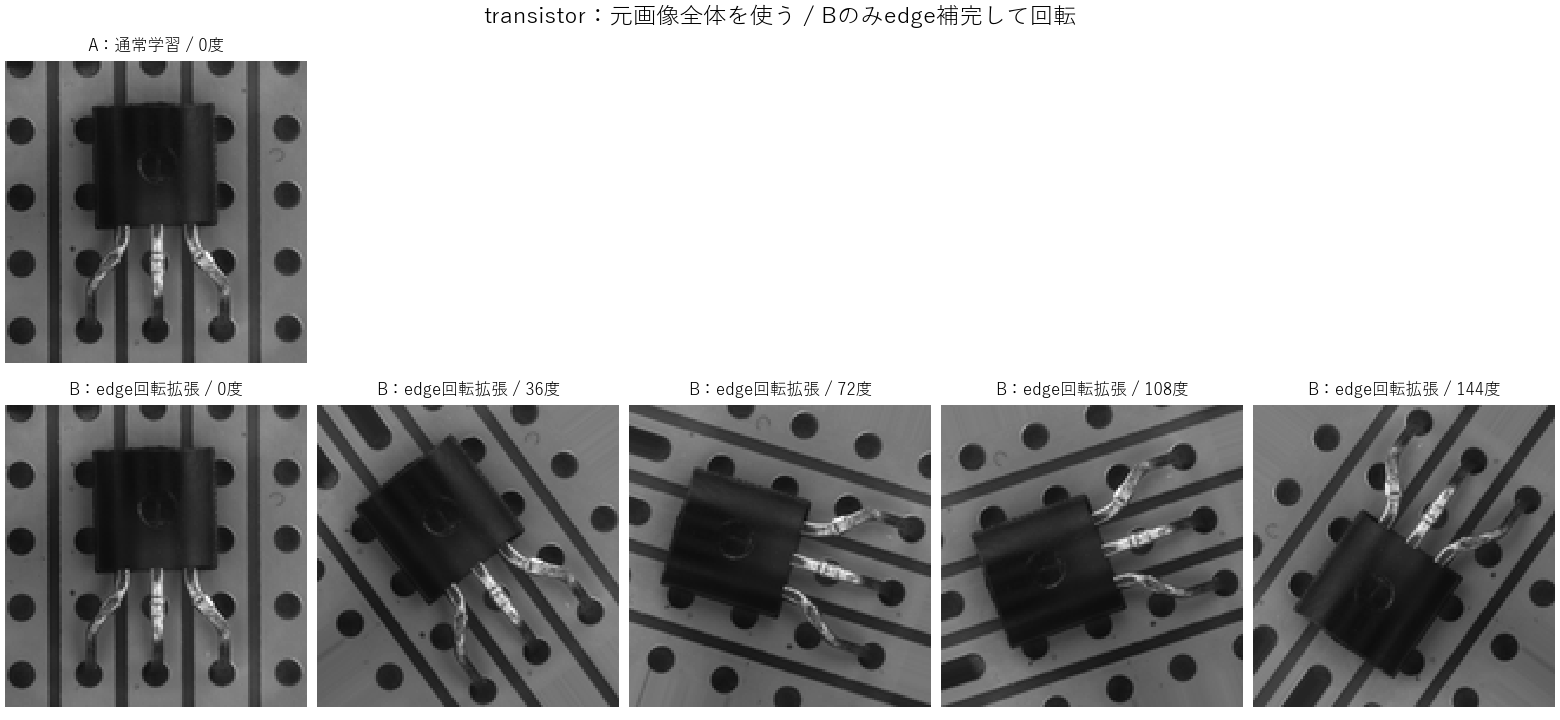

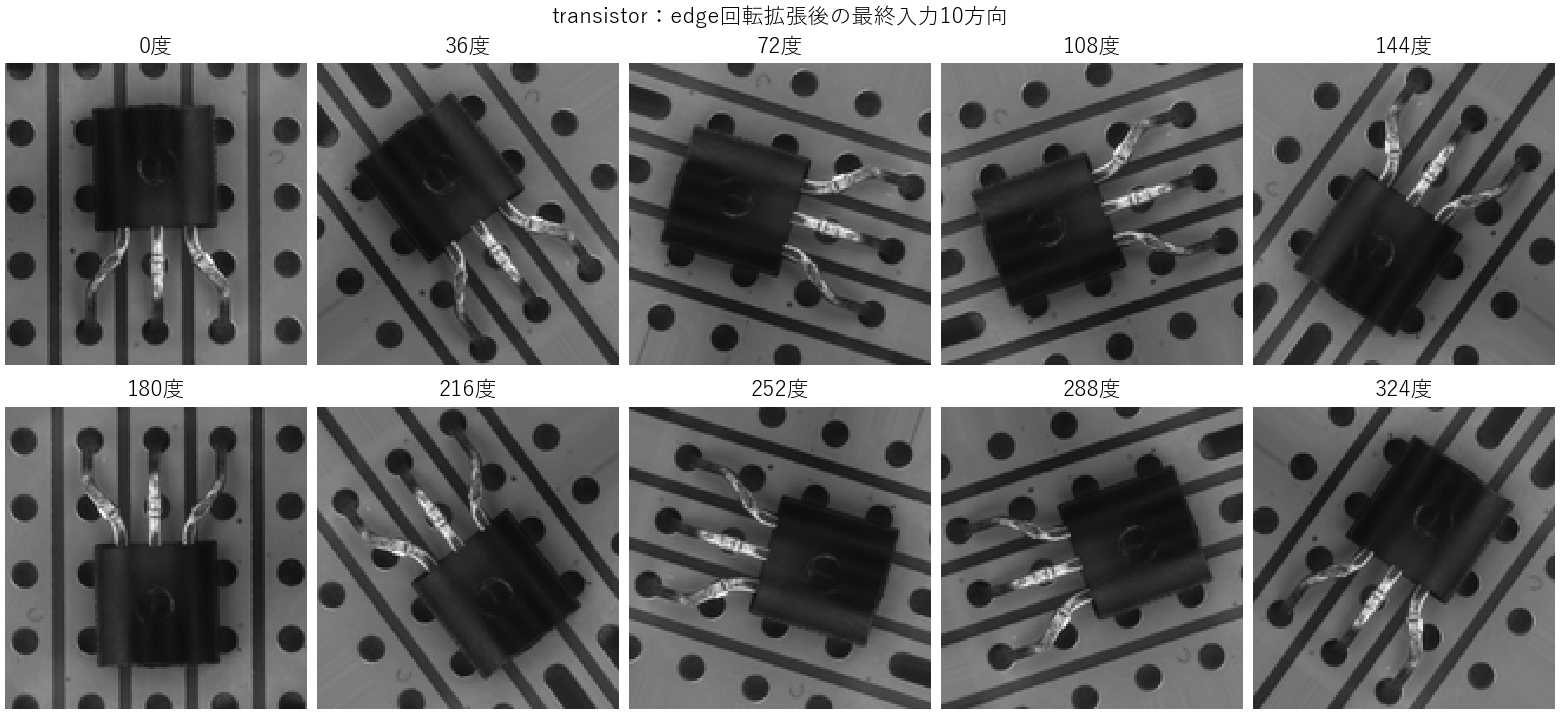

In [3]:
if PREPARE_TRAINING_DATA:
    fig,axes=plt.subplots(len(CONDITIONS),5,figsize=(13,6),constrained_layout=True)
    for row,name in enumerate(CONDITIONS):
        for col in range(5):
            if name=='A_original' and col>0:
                axes[row,col].set_visible(False)
                continue
            index=0 if name=='A_original' else col
            image,parent,variant=datasets[name][index]
            axes[row,col].imshow(image[0],cmap='gray',vmin=0,vmax=1,interpolation='nearest')
            angle=ANGLES[variant] if name=='B_rotate10' else 0
            axes[row,col].set_title(f'{CONDITION_LABELS[name]} / {angle}度',fontsize=10)
            axes[row,col].axis('off')
    fig.suptitle('transistor：元画像全体を使う / Bのみedge補完して回転',fontsize=14)
    plt.show();plt.close(fig)
    fig,axes=plt.subplots(2,5,figsize=(13,6),constrained_layout=True)
    for i,ax in enumerate(axes.flat):
        ax.imshow(datasets['B_rotate10'][i][0][0],cmap='gray',vmin=0,vmax=1,interpolation='nearest')
        ax.set_title(f'{ANGLES[i]}度'); ax.axis('off')
    fig.suptitle('transistor：edge回転拡張後の最終入力10方向')
    plt.show();plt.close(fig)
else:
    print('入力プレビューはPREPARE_TRAINING_DATA=Trueで表示します。')

## 3. モデル・損失・学習関数
capsule比較と同じHybrid CNN＋FCです。学習は潜在変数のサンプリング、評価は `model.eval()`・`sample=False`（平均μ）を使用します。

復元項は画素の二乗誤差の**合計SSE**、KLは標準正規分布に対する通常VAEのKLです。ログはそれぞれ画像枚数で割った値です。Sparse VAEの専用正則化は使いません。

βは `min(1, zero_based_epoch/50)`。表示epoch1で0、epoch51で1になります。前回コードと同じです。

In [4]:
class VAE_Hybrid_CNN_FC(nn.Module):
    def __init__(self, latent_dim=64):
        super(VAE_Hybrid_CNN_FC, self).__init__()

        # -------------------------------------------------------------
        # 【エンコーダ前半】 CNN_Deep5（空間圧縮: 128x128 -> 4x4）
        # -------------------------------------------------------------
        self.encoder_conv = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(16), nn.ReLU(),

            nn.Conv2d(16, 32, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(),

            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(),

            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(256), nn.ReLU()
        )

        # -------------------------------------------------------------
        # 【エンコーダ後半】 FC_Only（段階的圧縮: 4096次元 -> 128次元）
        # -------------------------------------------------------------
        self.encoder_fc = nn.Sequential(
            nn.Linear(256 * 4 * 4, 1024), nn.ReLU(),
            nn.Linear(1024, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU()
        )

        # 潜在空間へのマッピング（128次元 -> 64次元）
        self.fc_mu = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)

        # -------------------------------------------------------------
        # 【デコーダ前半】 FC_Only（段階的復元: 64次元 -> 4096次元）
        # -------------------------------------------------------------
        self.decoder_fc = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.ReLU(),
            nn.Linear(128, 256), nn.ReLU(),
            nn.Linear(256, 1024), nn.ReLU(),
            # ※CNNへ繋ぐため、最後はSigmoidではなくReLUを使用します
            nn.Linear(1024, 256 * 4 * 4), nn.ReLU()
        )

        # -------------------------------------------------------------
        # 【デコーダ後半】 CNN_Deep5（空間復元: 4x4 -> 128x128）
        # -------------------------------------------------------------
        self.decoder_conv = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(),

            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(),

            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(),

            nn.ConvTranspose2d(32, 16, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(16), nn.ReLU(),

            nn.ConvTranspose2d(16, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x, sample=True):
        # 1. CNNによる特徴抽出
        h = self.encoder_conv(x)
        h = torch.flatten(h, start_dim=1)

        # 2. FCによる段階的圧縮
        h = self.encoder_fc(h)

        # 3. 潜在変数の計算と安全装置（クランプ）
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        logvar = torch.clamp(logvar, min=-10.0, max=10.0)

        std = torch.exp(0.5 * logvar)
        z = mu + torch.randn_like(std) * std if sample else mu

        # 4. FCによる段階的復元
        h_recon = self.decoder_fc(z)
        h_recon = h_recon.view(-1, 256, 4, 4) # 4階テンソルに戻す

        # 5. CNNによる画像復元
        recon = self.decoder_conv(h_recon)

        return recon, mu, logvar

def vae_loss(recon_x, x, mu, logvar, beta=1.0):  
    MSE = nn.functional.mse_loss(recon_x, x, reduction='sum')
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return MSE, KLD, MSE + beta * KLD

def seed_everything(seed):
    random.seed(int(seed))
    np.random.seed(int(seed))
    torch.manual_seed(int(seed))
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(int(seed))

def copy_cpu_state(model):
    return {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}

def state_digest(state):
    digest = hashlib.sha256()
    for name in sorted(state):
        tensor = state[name].detach().cpu().contiguous()
        digest.update(name.encode('utf-8') + str(tensor.dtype).encode('ascii'))
        digest.update(tensor.numpy().tobytes())
    return digest.hexdigest()

def make_initial_state(seed):
    seed_everything(seed)
    initial_model = VAE_Hybrid_CNN_FC(latent_dim=LATENT_DIM)
    return copy_cpu_state(initial_model)

def new_model(initial_state, seed, device=DEVICE):
    model = VAE_Hybrid_CNN_FC(latent_dim=LATENT_DIM).to(device)
    model.load_state_dict(initial_state, strict=True)
    # モデル構築で消費された乱数を戻し、各条件のサンプリング列を揃える。
    seed_everything(seed)
    return model

In [5]:
def train_epoch(model, loader, optimizer, beta, device, order_digest, max_batches=None):
    model.train()
    sums = np.zeros(3, dtype=np.float64)
    seen, updates = 0, 0
    for images, parents, variants in loader:
        if max_batches is not None and updates >= max_batches:
            break
        pair_order = torch.stack([parents, variants], dim=1).numpy().astype('<i8', copy=False)
        order_digest.update(pair_order.tobytes())
        images = images.to(device)
        optimizer.zero_grad(set_to_none=True)
        reconstruction, mu, logvar = model(images, sample=True)
        mse, kld, loss = vae_loss(reconstruction, images, mu, logvar, beta=beta)
        if not all(torch.isfinite(value).item() for value in [mse, kld, loss]):
            raise FloatingPointError('損失にNaN/infが発生しました。')
        loss.backward()
        if any(p.grad is not None and not torch.isfinite(p.grad).all().item() for p in model.parameters()):
            raise FloatingPointError('勾配にNaN/infが発生しました。')
        optimizer.step()
        sums += [mse.item(), kld.item(), loss.item()]
        seen += len(images)
        updates += 1
    if not seen:
        raise ValueError('学習バッチがありません。')
    return {'train_sse_per_image': float(sums[0] / seen),
            'train_kl_per_image': float(sums[1] / seen),
            'train_total_per_image': float(sums[2] / seen),
            'seen_images': seen, 'updates': updates}

def evaluate_normal(model, images, names, device=DEVICE):
    model.eval()
    rows = []
    with torch.inference_mode():
        for start in range(0, len(images), BATCH_SIZE):
            inputs = images[start:start + BATCH_SIZE].to(device)
            reconstruction, _, _ = model(inputs, sample=False)
            per_image = (inputs - reconstruction).square().flatten(1).sum(1).cpu().numpy()
            if not np.isfinite(per_image).all():
                raise FloatingPointError('評価誤差にNaN/infが発生しました。')
            for name, error in zip(names[start:start + BATCH_SIZE], per_image):
                rows.append({'path': name, 'sse_per_image': float(error),
                             'mse_per_pixel': float(error / (128 * 128))})
    return pd.DataFrame(rows)

def write_json(path, value):
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')

def train_condition(condition, seed, initial_state, directory):
    directory.mkdir(parents=True, exist_ok=False)
    dataset = datasets[condition]
    loader = loader_for(dataset, seed)
    model = new_model(initial_state, seed)
    initial_hash = state_digest(copy_cpu_state(model))
    if initial_hash != state_digest(initial_state):
        raise AssertionError('初期重みが一致しません。')
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    order_digest = hashlib.sha256()
    history = []
    total_updates = 0
    started = time.perf_counter()
    for epoch in range(EPOCHS):
        beta = min(1.0, epoch / ANNEALING_EPOCHS)
        values = train_epoch(model, loader, optimizer, beta, DEVICE, order_digest)
        assert values['seen_images'] == len(dataset) and values['updates'] == len(loader)
        total_updates += values['updates']
        history.append({'epoch': epoch + 1, 'beta': beta,
                        'cumulative_updates': total_updates, **values})
        pd.DataFrame(history).to_csv(directory / 'history.csv', index=False)
        if epoch == 0 or (epoch + 1) % 10 == 0 or epoch + 1 == EPOCHS:
            print(f'{condition} / seed={seed} / epoch={epoch + 1:3d}/{EPOCHS} '
                  f'/ beta={beta:.2f} / train SSE={values["train_sse_per_image"]:.4f} '
                  f'/ updates={total_updates}', flush=True)

    assert total_updates == EPOCHS * math.ceil(len(dataset) / BATCH_SIZE)
    # エポック選択はせず、固定した最終エポックだけを共通テストで確認する。
    normal_results = evaluate_normal(model, normal_test_tensor,
                                     [r['path'] for r in normal_test_manifest])
    normal_results.to_csv(directory / 'normal_test_errors.csv', index=False)
    torch.save(copy_cpu_state(model), directory / 'model_final.pth')
    history_frame = pd.DataFrame(history)
    fig, ax = plt.subplots(figsize=(12, 7))
    for column, label, style in [
        ('train_total_per_image', 'Total Loss', '-'),
        ('train_sse_per_image', 'Reconstruction SSE', '--'),
        ('train_kl_per_image', 'KL', '-.'),
    ]:
        ax.plot(history_frame.epoch, np.maximum(history_frame[column], 1e-12),
                linestyle=style, label=label)
    ax.set(xlabel='エポック', ylabel='1画像あたりの損失', yscale='log')
    ax.set_title(f'{CONDITION_LABELS[condition]} / seed={seed}', fontsize=16)
    ax.grid(True, which='both', linestyle='--', alpha=0.7)
    ax.legend()
    fig.tight_layout()
    fig.savefig(directory / 'learning_curve.png', dpi=150)
    plt.close(fig)
    summary = {
        'condition': condition, 'seed': int(seed), 'epochs': EPOCHS,
        'images_per_epoch': len(dataset), 'updates': total_updates,
        'initial_state_sha256': initial_hash,
        'sample_order_sha256': order_digest.hexdigest(),
        'final_train_sse_per_image': history[-1]['train_sse_per_image'],
        'normal_test_sse_per_image': float(normal_results.sse_per_image.mean()),
        'normal_test_mse_per_pixel': float(normal_results.mse_per_pixel.mean()),
        'normal_test_inference': 'posterior mean, no sampling',
        'seconds': time.perf_counter() - started,
    }
    write_json(directory / 'summary.json', summary)
    del optimizer, model
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return summary

In [6]:
def binary_roc_curve(y_true, scores):
    labels = np.asarray(y_true)
    scores = np.asarray(scores, dtype=float)
    if labels.ndim != 1 or scores.ndim != 1 or labels.shape != scores.shape:
        raise ValueError('ラベルとスコアは同じ長さの1次元配列にしてください。')
    if not np.isfinite(scores).all() or not np.isin(labels, [0, 1]).all():
        raise ValueError('スコアは有限値、ラベルは0または1である必要があります。')
    positives = int((labels == 1).sum())
    negatives = int((labels == 0).sum())
    if not positives or not negatives:
        raise ValueError('正常と異常の両方が必要です。')
    order = np.argsort(-scores, kind='stable')
    ordered_scores = scores[order]
    ordered_labels = labels[order]
    ends = np.r_[np.flatnonzero(np.diff(ordered_scores)), len(scores) - 1]
    true_positives = np.cumsum(ordered_labels)[ends]
    false_positives = (ends + 1) - true_positives
    fpr = np.r_[0.0, false_positives / negatives]
    tpr = np.r_[0.0, true_positives / positives]
    thresholds = np.r_[np.inf, ordered_scores[ends]]
    return fpr, tpr, thresholds

def binary_auroc(y_true, scores):
    fpr, tpr, _ = binary_roc_curve(y_true, scores)
    return float(np.trapezoid(tpr, fpr))

assert binary_auroc([0,0,1,1], [0.1,0.2,0.8,0.9]) == 1.0
assert binary_auroc([0,0,1,1], [0.9,0.8,0.2,0.1]) == 0.0
assert binary_auroc([0,0,1,1], [0.5,0.5,0.5,0.5]) == 0.5


def score_model(model_path,images,batch_size=EVAL_BATCH_SIZE):
    model=VAE_Hybrid_CNN_FC(latent_dim=64).to(DEVICE)
    model.load_state_dict(torch.load(model_path,map_location=DEVICE,weights_only=True),strict=True)
    model.eval()
    restored=np.empty((len(images),128,128),dtype=np.float32)
    maps=np.empty_like(restored)
    scores=np.empty(len(images),dtype=np.float64)
    errors=np.empty(len(images),dtype=np.float64)
    with torch.inference_mode():
        for start in range(0,len(images),batch_size):
            x=images[start:start+batch_size].to(DEVICE)
            recon,_,_=model(x,sample=False)
            assert torch.isfinite(recon).all()
            sse=(x-recon).square().flatten(1).sum(1).cpu().numpy()
            for local in range(len(x)):
                index=start+local
                original=x[local,0].cpu().numpy(); output=recon[local,0].cpu().numpy()
                _,smap=ssim(original,output,data_range=1.0,win_size=11,full=True)
                amap=1.0-smap
                assert np.isfinite(amap).all()
                restored[index]=output; maps[index]=amap
                scores[index]=np.mean(np.sort(amap.ravel())[::-1][:TOP_K])
                errors[index]=sse[local]
    del model
    return scores,{'reconstruction':restored,'anomaly_map':maps,'sse_per_image':errors}

def verify_auroc(y,scores):
    value=binary_auroc(y,scores)
    normal=scores[y==0]; abnormal=scores[y==1]
    rank=((abnormal[:,None]>normal).sum()+0.5*(abnormal[:,None]==normal).sum())/(len(normal)*len(abnormal))
    assert np.isclose(value,rank,atol=1e-12)
    return value

## 4. テスト画像を固定する
テスト全100枚を同じ前処理・順序で読み、ファイルと入力テンソルのSHA-256を記録します。訓練画像との重複も確認します。正解マスクは今回の画像単位AUROCには使用しません。

In [7]:
paths = sorted(TEST_DIR.glob('*/*.png'), key=lambda p: p.relative_to(TEST_DIR).as_posix())
counts = {name: sum(p.parent.name == name for p in paths) for name in category_labels}
if counts != {'good':60,'bent_lead':10,'cut_lead':10,'damaged_case':10,'misplaced':10}:
    raise ValueError(f'計画時の評価データ100枚と異なります: {counts}')

inputs, image_records = [], []
for path in paths:
    raw = path.read_bytes()
    with Image.open(BytesIO(raw)) as im:
        tensor = to_tensor(final_transform(im.convert('RGB')))
    inputs.append(tensor)
    image_records.append({
        'relative_path': path.relative_to(TEST_DIR).as_posix(),
        'repo_path': path.relative_to(ROOT).as_posix(),
        'category': path.parent.name,
        'category_ja': category_labels[path.parent.name],
        'true_label': int(path.parent.name != 'good'),
        'file_sha256': hashlib.sha256(raw).hexdigest(),
        'preprocessed_sha256': hashlib.sha256(tensor.numpy().tobytes()).hexdigest(),
    })
input_tensor = torch.stack(inputs)
image_table = pd.DataFrame(image_records)
assert tuple(input_tensor.shape) == (100,1,128,128)

manifest_hash = hashlib.sha256(json.dumps(image_records, ensure_ascii=False, sort_keys=True).encode('utf-8')).hexdigest()
display(pd.DataFrame([{'種類': category_labels[name], '枚数': count} for name,count in counts.items()]))
print(f'評価データ識別値：{manifest_hash}')
if PREPARE_TRAINING_DATA:
    assert not {r['file_sha256'] for r in train_manifest} & {r['file_sha256'] for r in image_records}
    assert not {r['preprocessed_sha256'] for r in train_manifest} & {r['preprocessed_sha256'] for r in image_records}

評価データ識別値：d7d8a95c32050c0e968424b9d628a4da8b25e68f9db30f2daaa40790ca46db82


,種類,枚数
0,正常,60
1,端子の曲がり,10
2,端子の切断,10
3,本体の損傷,10
4,配置ずれ,10


## 5. 少量の動作確認（正式実験ではありません）
各条件2バッチのみ学習し、保存・読み直し・平均推論・SSIM Top-130・AUROC計算を確認します。値は研究結果として報告しません。正式なモデル・評価結果フォルダは作りません。

In [8]:
smoke_report = []
if RUN_SMOKE_TEST and PREPARE_TRAINING_DATA:
    smoke_seed = 123
    smoke_sets = {name: RotationControlDataset(train_images[:2], name) for name in CONDITIONS}
    # Aも2バッチ実行できるよう、動作確認に限り元画像を4枚使う。
    smoke_sets['A_original'] = RotationControlDataset(train_images[:4], 'A_original')
    initial = make_initial_state(smoke_seed)
    initial_hash = state_digest(initial)
    for name in CONDITIONS:
        ds = smoke_sets[name]
        batch = 2 if name == 'A_original' else 4
        loader = loader_for(ds, smoke_seed, batch_size=batch)
        model = new_model(initial, smoke_seed, device=torch.device('cpu'))
        assert state_digest(copy_cpu_state(model)) == initial_hash
        optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
        digest = hashlib.sha256()
        metrics = train_epoch(model, loader, optimizer, beta=0.0,
                              device=torch.device('cpu'), order_digest=digest, max_batches=2)
        assert metrics['updates'] == 2
        check = evaluate_normal(model, normal_test_tensor[:2],
                                [r['path'] for r in normal_test_manifest[:2]], device=torch.device('cpu'))
        assert len(check) == 2 and np.isfinite(check.sse_per_image).all()
        # 一時領域で保存・再読込し、平均推論が完全に一致することを確認。
        with tempfile.TemporaryDirectory(prefix='transistor_train_smoke_') as tmp:
            weight_path=Path(tmp)/'smoke_only.pth'
            torch.save(copy_cpu_state(model),weight_path)
            restored=VAE_Hybrid_CNN_FC(latent_dim=LATENT_DIM)
            restored.load_state_dict(torch.load(weight_path,map_location='cpu',weights_only=True))
            restored.eval(); model.eval()
            with torch.inference_mode():
                x=normal_test_tensor[:2]
                assert torch.equal(model(x,sample=False)[0],restored(x,sample=False)[0])
            del restored
        smoke_report.append({'condition': name, 'updates': metrics['updates'],
                             'initial_state_sha256': initial_hash,
                             'sample_order_sha256': digest.hexdigest(),
                             'status': '動作確認のみ：正常終了'})
        with tempfile.TemporaryDirectory(prefix='transistor_score_smoke_') as temp:
            path=Path(temp)/'smoke.pth';torch.save(copy_cpu_state(model),path)
            indices=np.r_[np.flatnonzero(image_table.true_label.to_numpy()==0)[:2],
                          np.flatnonzero(image_table.true_label.to_numpy()==1)[:2]]
            scores1,cache1=score_model(path,input_tensor[indices],batch_size=2)
            scores2,cache2=score_model(path,input_tensor[indices],batch_size=2)
            assert np.array_equal(scores1,scores2)
            assert np.array_equal(cache1['reconstruction'],cache2['reconstruction'])
            verify_auroc(image_table.true_label.to_numpy()[indices],scores1)
            expected=np.sort(cache1['anomaly_map'].reshape(len(indices),-1),axis=1)[:,-TOP_K:].mean(1)
            assert np.allclose(scores1,expected,atol=1e-7)
        del model, optimizer
    assert len({v['initial_state_sha256'] for v in smoke_report}) == 1
    display(pd.DataFrame(smoke_report)[['condition', 'updates', 'status']])
    print('両条件の同一初期重み、有限な損失・勾配・平均推論を確認。正式学習は未実施。')
    del initial, smoke_sets
else:
    print('動作確認はスキップしました。')

両条件の同一初期重み、有限な損失・勾配・平均推論を確認。正式学習は未実施。


,condition,updates,status
0,A_original,2,動作確認のみ：正常終了
1,B_rotate10,2,動作確認のみ：正常終了


## 6. 正式学習（初期設定では実行しません）
`RUN_FULL_TRAINING=True` にして実行します。設定・データ識別情報・学習ログ・最終モデルを実行ごとの新規フォルダへ保存します。中断した実行を完了済みとして評価しません。

元画像213枚と初期重みは両条件で共通です。ただし100エポックでAは700更新、Bは6,700更新となり、回転による入力変化と更新量の増加が含まれます。回転だけの効果を切り分けた比較ではありません。単一seedの結果のみで一般的な優劣や形状だけの因果関係は断定しません。

In [9]:
run_dir = None
comparison_results = []
if RUN_FULL_TRAINING:
    run_id = datetime.now(ZoneInfo('Asia/Tokyo')).strftime('%Y%m%d_%H%M%S') + '_' + uuid.uuid4().hex[:8]
    run_dir = OUTPUT_BASE / run_id
    run_dir.mkdir(parents=True, exist_ok=False)
    versions = {package: importlib.metadata.version(package)
                for package in ['torch', 'torchvision', 'numpy', 'Pillow']}
    config = {
        'experiment':EXPERIMENT,'run_id':run_id,'dataset':'transistor',
        'conditions':list(CONDITIONS),'design_version':3,
        'comparison_note':'A/B have different update counts; not an isolated rotation-only effect',
        'seeds':SEEDS,'epochs':EPOCHS,'batch_size':BATCH_SIZE,'optimizer':'Adam',
        'learning_rate':LEARNING_RATE,'latent_dim':LATENT_DIM,'annealing_epochs':ANNEALING_EPOCHS,
        'beta_rule':'min(1.0, zero_based_epoch / annealing_epochs)',
        'angles':list(ANGLES),'rotation_interpolation':'NEAREST','rotation_expand':False,
        'rotation_background':'edge','padding_formula':'ceil((hypot(width,height)-min(width,height))/2)+4',
        'edge_pad_width_by_source_size':{'1024x1024':edge_pad_width(EXPECTED_SOURCE_SIZE)},
        'supported_original_pixels':'preserve original rotate NEAREST values before resizing',
        'rotation_stage':'full_resolution_before_resize','rotation_input_size':[1024,1024],
        'source_size':[1024,1024],'center_crop':False,'network_input_size':[128,128],
        'preprocessing':'Full image RGB, optional edge rotation at1024, Resize128 LANCZOS, Grayscale, ToTensor',
        'preprocessing_by_condition':{
            'A_original':'Full RGB -> Resize128 LANCZOS -> Grayscale -> ToTensor',
            'B_rotate10':'Full RGB -> edge pad -> Rotate NEAREST -> central1024 -> preserve original-supported pixels -> Resize128 LANCZOS -> Grayscale -> ToTensor'},
        'test_preprocessing':'Full RGB -> Resize128 LANCZOS -> Grayscale -> ToTensor',
        'training_loss':'sum pixel squared error + beta * sum standard-normal KL',
        'training_inference':'posterior sampling','normal_test_inference':'posterior mean',
        'train_normal_count':213,'test_normal_count':60,
        'device':str(DEVICE),'python':platform.python_version(),'versions':versions,
        'torch_threads':torch.get_num_threads(),'status':'running',
    }
    write_json(run_dir / 'config.json', config)
    write_json(run_dir / 'train_manifest.json', train_manifest)
    write_json(run_dir / 'normal_test_manifest.json', normal_test_manifest)
    write_json(run_dir / 'test_manifest.json', image_records)
    config['test_manifest_sha256']=manifest_hash
    write_json(run_dir/'config.json',config)
    condition_table.to_csv(run_dir / 'conditions.csv', index=False)
    augmentation_manifest=[]
    for name,ds in datasets.items():
        for index in range(len(ds)):
            tensor,parent,variant=ds[index]
            augmentation_manifest.append({'condition':name,'index':index,'source_path':train_manifest[parent]['path'],
                'source_sha256':train_manifest[parent]['file_sha256'],'parent':parent,'variant':variant,
                'angle':ANGLES[variant] if name=='B_rotate10' else 0,
                'preprocessed_sha256':hashlib.sha256(tensor.numpy().tobytes()).hexdigest()})
    write_json(run_dir/'augmentation_manifest.json',augmentation_manifest)
    del augmentation_manifest
    try:
        for seed in SEEDS:
            initial = make_initial_state(seed)
            summaries = []
            for name in CONDITIONS:
                summary = train_condition(name, seed, initial, run_dir / f'seed_{seed}' / name)
                summaries.append(summary)
                comparison_results.append(summary)
                pd.DataFrame(comparison_results).to_csv(run_dir / 'comparison.csv', index=False)
            assert len({v['initial_state_sha256'] for v in summaries}) == 1
            del initial
        config['status'] = 'completed'
        write_json(run_dir / 'config.json', config)
        print(f'正式学習と共通正常画像の評価が完了：{run_dir}')
        print(f'保存済みモデルのEVALUATION_RUN_IDに指定する値：{run_id}')
    except BaseException as exc:
        config['status'] = 'interrupted_or_failed'
        config['error'] = f'{type(exc).__name__}: {exc}'
        write_json(run_dir / 'config.json', config)
        raise
else:
    print('RUN_FULL_TRAINING=False：2条件×100エポックの正式学習は実行していません。')
    print('正式学習を行う場合は設定をTrueにして、上から実行してください。')

RUN_FULL_TRAINING=False：2条件×100エポックの正式学習は実行していません。
正式学習を行う場合は設定をTrueにして、上から実行してください。


## 7. 保存済み実行を読み込む（ここから先は再学習不要）
上の設定・前処理関数・モデル・テスト準備を実行した後に使用します。EVALUATION_RUN_IDがNoneなら、このノートブックで作った実行、または最新の完了済み実行を選びます。指定した実行が未完了・不整合ならエラーにします。

再起動後は先頭で正式学習・回転準備・動作確認をFalseにして上から実行できます。設定とデータ識別情報を照合し、最終モデルのみ評価します。

In [10]:
def read_json(path): return json.loads(path.read_text(encoding='utf-8'))
def sha256(path): return hashlib.sha256(path.read_bytes()).hexdigest()
completed=[]
if OUTPUT_BASE.is_dir():
    for candidate in sorted(OUTPUT_BASE.iterdir()):
        if (candidate/'config.json').is_file():
            c=read_json(candidate/'config.json')
            if c.get('experiment')==EXPERIMENT and c.get('status')=='completed':completed.append(candidate)
RUN_DIR=(OUTPUT_BASE/EVALUATION_RUN_ID if EVALUATION_RUN_ID is not None else
         (run_dir if run_dir is not None and read_json(run_dir/'config.json')['status']=='completed'
          else (completed[-1] if completed else None)))
READY=RUN_DIR is not None
RESULT_DIR=None
if READY:
    RUN_ID=RUN_DIR.name; SEED=EVALUATION_SEED
    train_config=read_json(RUN_DIR/'config.json')
    assert train_config['experiment']==EXPERIMENT and train_config['status']=='completed'
    assert train_config['conditions']==list(CONDITIONS) and train_config['design_version']==3
    assert train_config['epochs']==100 and train_config['batch_size']==32
    assert train_config['latent_dim']==64 and train_config['source_size']==[1024,1024]
    assert train_config['rotation_background']=='edge' and train_config['rotation_stage']=='full_resolution_before_resize'
    assert train_config['angles']==list(ANGLES) and train_config['center_crop'] is False
    assert train_config['test_manifest_sha256']==manifest_hash,'学習時と評価データが異なります。'
    saved_train=read_json(RUN_DIR/'train_manifest.json')
    for row in saved_train:
        assert sha256(ROOT/row['path'])==row['file_sha256'],'訓練画像が変更されています。'
    assert not {r['file_sha256'] for r in saved_train}&{r['file_sha256'] for r in image_records}
    assert not {r['preprocessed_sha256'] for r in saved_train}&{r['preprocessed_sha256'] for r in image_records}
    model_paths={name:RUN_DIR/f'seed_{SEED}'/name/'model_final.pth' for name in CONDITIONS}
    summaries={name:read_json(path.parent/'summary.json') for name,path in model_paths.items()}
    assert all(path.is_file() for path in model_paths.values())
    assert all(v['seed']==SEED and v['epochs']==100 for v in summaries.values())
    assert len({v['initial_state_sha256'] for v in summaries.values()})==1
    assert summaries['A_original']['updates']==700
    assert summaries['B_rotate10']['updates']==6700
    before_model_hashes={name:sha256(p) for name,p in model_paths.items()}
    print(f'評価対象：{RUN_ID} / seed{SEED} / 平均推論 / {DEVICE}')
else:
    print('正式学習は未実施です。以降の正式グラフ・比較表は学習完了後に表示します。')

正式学習は未実施です。以降の正式グラフ・比較表は学習完了後に表示します。


## 8. 学習曲線：学習データ上のSSE・KL・総損失
2条件の復元SSEを重ねた図と、各条件の総損失・SSE・KLを表示します。学習対象が異なるため、このSSEだけで復元性能や異常検知性能の優劣を決めません。総損失には変化するβが含まれます。

In [11]:
def plot_histories(directory,seed,save_dir=None):
    histories={name:pd.read_csv(directory/f'seed_{seed}'/name/'history.csv') for name in CONDITIONS}
    fig,ax=plt.subplots(figsize=(11,6),constrained_layout=True)
    for name,h in histories.items():
        ax.plot(h.epoch,h.train_sse_per_image,label=LABELS[name],color=COLORS[name])
    ax.set(xlabel='エポック',ylabel='学習画像1枚あたりの復元SSE',title='transistor：学習曲線（学習データ上の誤差）')
    ax.grid(ls='--',alpha=.5);ax.legend()
    if save_dir:fig.savefig(save_dir/'train_sse.png',dpi=160)
    plt.show();plt.close(fig)
    fig,axes=plt.subplots(1,len(CONDITIONS),figsize=(12,5),constrained_layout=True)
    for ax,name in zip(axes,CONDITIONS):
        h=histories[name]
        for key,label in [('train_total_per_image','総損失'),('train_sse_per_image','復元SSE'),('train_kl_per_image','KL')]:
            ax.plot(h.epoch,np.maximum(h[key],1e-12),label=label)
        ax.set(title=LABELS[name],xlabel='エポック',ylabel='1画像あたりの値（対数軸）',yscale='log')
        ax.legend();ax.grid(ls='--',alpha=.5)
    if save_dir:fig.savefig(save_dir/'training_losses.png',dpi=160)
    plt.show();plt.close(fig)
if READY:plot_histories(RUN_DIR,SEED)
else:print('正式学習ログ待ちです。')

正式学習ログ待ちです。


## 9. 共通100枚でAUROC評価
SSIM（窓11×11、data_range=1）のマップから1−SSIMを計算し、上位130**点**の平均を画像スコアとします。130個の独立パッチではありません。スコアが高いほど異常とします。

評価指標はAUROCのみ。正常画像のSSE/MSEは補助情報です。正常画像60枚の復元品質と、正常・異常の分離能力を区別します。閾値は探索しません。

In [12]:
all_scores={}; reconstruction_cache={}; summary_rows=[]
comparison=pd.DataFrame()
if READY:
    for name in CONDITIONS:
        scores,cache=score_model(model_paths[name],input_tensor)
        y=image_table.true_label.to_numpy()
        auc=verify_auroc(y,scores)
        normal_sse=float(cache['sse_per_image'][y==0].mean())
        recorded=float(summaries[name]['normal_test_sse_per_image'])
        assert np.isclose(normal_sse,recorded,rtol=1e-5,atol=1e-4),(name,normal_sse,recorded)
        all_scores[name]=scores; reconstruction_cache[name]=cache
        summary_rows.append({'condition':name,'seed':SEED,'auroc':auc,
            'normal_test_sse_per_image':normal_sse,'normal_test_mse_per_pixel':normal_sse/(128*128),
            'final_train_sse_per_image':summaries[name]['final_train_sse_per_image'],
            'updates':summaries[name]['updates'],'model_sha256':sha256(model_paths[name])})
        print(f'{LABELS[name]}：AUROC={auc:.6f} / 共通正常画像SSE={normal_sse:.6f}')
    comparison=pd.DataFrame(summary_rows)
    RESULT_DIR=RUN_DIR/'evaluations'/(datetime.now(ZoneInfo('Asia/Tokyo')).strftime('%Y%m%d_%H%M%S')+'_'+uuid.uuid4().hex[:8])
    RESULT_DIR.mkdir(parents=True,exist_ok=False)
else:
    print('正式学習後に実行すると、2モデルのAUROCと共通正常画像の復元誤差を比較します。')

正式学習後に実行すると、2モデルのAUROCと共通正常画像の復元誤差を比較します。


## 10. AUROC比較表・棒グラフ・ROC曲線・スコア分布

In [13]:
if READY:
    display(comparison[['condition','seed','updates','auroc',
                        'normal_test_sse_per_image','normal_test_mse_per_pixel',
                        'final_train_sse_per_image']].rename(columns={
        'condition':'条件','seed':'学習seed','updates':'更新回数','auroc':'AUROC',
        'normal_test_sse_per_image':'共通正常画像のSSE/画像',
        'normal_test_mse_per_pixel':'共通正常画像のMSE/画素',
        'final_train_sse_per_image':'最終エポックの学習SSE/画像',
    }).style.format({'AUROC':'{:.6f}','共通正常画像のSSE/画像':'{:.4f}',
                     '共通正常画像のMSE/画素':'{:.6f}','最終エポックの学習SSE/画像':'{:.4f}'}))

    fig, ax = plt.subplots(figsize=(9,5.5))
    values = comparison.set_index('condition').loc[list(CONDITIONS),'auroc'].to_numpy()
    ax.bar(np.arange(len(CONDITIONS)),values,color=[COLORS[name] for name in CONDITIONS],width=0.55)
    ax.set_xticks(np.arange(len(CONDITIONS)),[LABELS[name] for name in CONDITIONS])
    ax.set_ylim(0,1.08)
    ax.set_yticks(np.linspace(0,1,6))
    ax.set_ylabel('AUROC（大きいほどよい）',fontsize=14)
    ax.set_title('通常学習・回転拡張モデルのAUROC比較',fontsize=16,fontweight='bold')
    for i,value in enumerate(values):
        ax.text(i,value+0.02,f'{value:.4f}',ha='center',fontsize=14,fontweight='bold')
    ax.grid(axis='y',linestyle='--',alpha=0.5)
    ax.set_axisbelow(True)
    fig.tight_layout()
    fig.savefig(RESULT_DIR/'auroc_comparison.png',dpi=150)
    plt.show()
    plt.close(fig)

    winner = comparison.loc[comparison.auroc.idxmax()]
    display(Markdown(f'今回の単一シードの比較で最も高いAUROCは **{LABELS[winner.condition]}：{winner.auroc:.4f}** です。'
                     '学習シードを変えたときのばらつきや、有意な優劣はまだ確認していません。'))
else:
    print('正式結果待ち：この比較表示はまだありません。')

正式結果待ち：この比較表示はまだありません。


In [14]:
if READY:
    fig, ax = plt.subplots(figsize=(8,8))
    for name in CONDITIONS:
        fpr,tpr,_ = binary_roc_curve(image_table.true_label.to_numpy(),all_scores[name])
        auc_value = float(comparison.loc[comparison.condition==name,'auroc'].iloc[0])
        ax.plot(fpr,tpr,color=COLORS[name],lw=2,label=f'{LABELS[name]} (AUROC = {auc_value:.4f})')
    ax.set_xlim([0.0,1.0])
    ax.set_ylim([0.0,1.05])
    ax.set_xlabel('False Positive Rate (偽陽性率 / 過剰検知)',fontsize=14)
    ax.set_ylabel('True Positive Rate (真陽性率 / 再現率)',fontsize=14)
    ax.set_title(f'ROC Curve (transistor / Hybrid CNN + FC / seed{SEED})',fontsize=16,fontweight='bold')
    ax.legend(loc='lower right',fontsize=12)
    ax.grid(True,linestyle='--',alpha=0.7)
    fig.tight_layout()
    fig.savefig(RESULT_DIR/'roc_comparison.png',dpi=150)
    plt.show()
    plt.close(fig)
else:
    print('正式結果待ち：この比較表示はまだありません。')

正式結果待ち：この比較表示はまだありません。


In [15]:
if READY:
    joined_scores = np.concatenate([all_scores[name] for name in CONDITIONS])
    lo,hi=float(joined_scores.min()),float(joined_scores.max())
    if hi<=lo: lo-=1e-6;hi+=1e-6
    common_bins = np.linspace(lo,hi,40)
    y = image_table.true_label.to_numpy()
    max_count = max(np.histogram(all_scores[name][y==label],bins=common_bins)[0].max()
                    for name in CONDITIONS for label in [0,1])
    for name in CONDITIONS:
        fig,ax = plt.subplots(figsize=(10,6))
        ax.hist(all_scores[name][y==0],bins=common_bins,color='green',alpha=0.5,
                edgecolor='white',linewidth=0.5,label='正常 (Good)')
        ax.hist(all_scores[name][y==1],bins=common_bins,color='red',alpha=0.5,
                edgecolor='white',linewidth=0.5,label='異常 (Anomaly)')
        ax.set_xlim(common_bins[0],common_bins[-1])
        ax.set_ylim(0,max_count+1)
        ax.set_title(f'異常スコアの分布 ({LABELS[name]} | SSIM Top-{TOP_K})',fontsize=16,fontweight='bold')
        ax.set_xlabel(f'異常スコア (上位{TOP_K}点のSSIM誤差平均)',fontsize=14)
        ax.set_ylabel('画像の数 (Count)',fontsize=14)
        ax.legend(fontsize=12)
        ax.grid(axis='y',linestyle='--',alpha=0.7)
        fig.tight_layout()
        fig.savefig(RESULT_DIR/f'score_distribution_{name}.png',dpi=150)
        plt.show()
        plt.close(fig)
else:
    print('正式結果待ち：この比較表示はまだありません。')

正式結果待ち：この比較表示はまだありません。


## 11. 異常種類別AUROC（補足）
正常60枚と各異常10枚を比較します。全体AUROCと同じスコアを使い、種類ごとにスコアの定義やモデルを調整しません。各異常が少数・単一seedであるため、値の差を確定的な優劣とは解釈しません。配置ずれの検出に回転学習がどう影響するかも確認します。

In [16]:
category_auroc=pd.DataFrame()
if READY:
    rows=[]
    for category in category_labels:
        if category=='good':continue
        selected=image_table.category.isin(['good',category]).to_numpy()
        for name in CONDITIONS:
            rows.append({'condition':name,'category':category,'category_ja':category_labels[category],
                         'normal_count':60,'anomaly_count':10,
                         'auroc':verify_auroc(image_table.true_label.to_numpy()[selected],all_scores[name][selected])})
    category_auroc=pd.DataFrame(rows)
    display(category_auroc.pivot(index='category_ja',columns='condition',values='auroc'))
    fig,ax=plt.subplots(figsize=(11,6),constrained_layout=True)
    table=category_auroc.pivot(index='category_ja',columns='condition',values='auroc').loc[:,list(CONDITIONS)]
    table.rename(columns=LABELS).plot.bar(ax=ax,color=[COLORS[n] for n in CONDITIONS],rot=0)
    ax.set(ylim=(0,1.08),xlabel='異常種類（各10枚）',ylabel='AUROC',title='種類別AUROC：各異常と正常60枚の比較（補足）')
    ax.grid(axis='y',ls='--',alpha=.5);ax.set_axisbelow(True)
    fig.savefig(RESULT_DIR/'category_auroc.png',dpi=160);plt.show();plt.close(fig)
else:print('正式結果待ちです。')

正式結果待ちです。


## 12. 入力・復元・誤差マップを同じ推論結果で比較
初期表示は各種類1枚、計5枚です。先頭の `MAX_IMAGES_PER_CATEGORY=None` で全100枚を表示できます。全モデルで誤差マップの色範囲は0〜2に固定します。入力・復元は0〜1です。

誤差マップは入力との差であり、欠陥の正解位置ではありません。正常／異常の判定や閾値は追加しません。

In [17]:
VISUALIZE_CATEGORIES=None  # 例：['good','misplaced']
VISUALIZE_PATHS=None  # 例：['good/000.png']
VISUAL_MAP_VMIN=0.0;VISUAL_MAP_VMAX=2.0
def show_category_reconstructions(category):
    if VISUALIZE_CATEGORIES is not None and category not in VISUALIZE_CATEGORIES:
        print(f'{category_labels[category]}：設定により表示しません。')
        return 0
    selected = image_table.index[image_table.category == category].tolist()
    if VISUALIZE_PATHS is not None:
        selected = [index for index in selected if image_table.loc[index, 'relative_path'] in VISUALIZE_PATHS]
    if MAX_IMAGES_PER_CATEGORY is not None:
        selected = selected[:MAX_IMAGES_PER_CATEGORY]
    print(f'{category_labels[category]}（{category}）：{len(selected)}枚 / 全{counts[category]}枚')
    for index in selected:
        record = image_table.loc[index]
        original = input_tensor[index, 0].cpu().numpy()
        fig, axes = plt.subplots(len(CONDITIONS), 3, figsize=(9, 6.5), dpi=100)
        fig.subplots_adjust(left=0.08, right=0.85, bottom=0.03, top=0.89, wspace=0.25, hspace=0.35)
        for row, name in enumerate(CONDITIONS):
            output = reconstruction_cache[name]['reconstruction'][index]
            error_map = reconstruction_cache[name]['anomaly_map'][index]
            axes[row, 0].imshow(original, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
            axes[row, 1].imshow(output, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
            heat = axes[row, 2].imshow(error_map, cmap='inferno', vmin=VISUAL_MAP_VMIN,
                                      vmax=VISUAL_MAP_VMAX, interpolation='nearest')
            axes[row, 0].set_title('入力画像', fontsize=11)
            axes[row, 0].set_ylabel(LABELS[name], fontsize=10)
            axes[row, 1].set_title(f'復元画像\n異常スコア = {all_scores[name][index]:.6f}', fontsize=10)
            axes[row, 2].set_title('誤差マップ（1−SSIM）', fontsize=10)
            for ax in axes[row]:
                ax.set_xticks([]); ax.set_yticks([])
        colorbar_axis = fig.add_axes([0.88, 0.08, 0.025, 0.76])
        bar = fig.colorbar(heat, cax=colorbar_axis)
        bar.set_label('SSIM誤差：明るいほど違いが大きい', fontsize=9)
        fig.suptitle(f'{record.relative_path} / 正解：{record.category_ja}\n'
                     f'transistor・平均推論 / seed={SEED} / 入力と復元は0〜1、誤差の色範囲は全図共通', fontsize=11)
        fig.canvas.draw()
        plt.show()
        plt.close(fig)
    if not selected:
        print('表示条件に該当する画像はありません。')
    return len(selected)

if READY:
    if MAX_IMAGES_PER_CATEGORY is not None:
        assert isinstance(MAX_IMAGES_PER_CATEGORY,int) and not isinstance(MAX_IMAGES_PER_CATEGORY,bool) and MAX_IMAGES_PER_CATEGORY>0
    for name in CONDITIONS:
        expected=np.sort(reconstruction_cache[name]['anomaly_map'].reshape(len(image_table),-1),axis=1)[:,-TOP_K:].mean(1)
        assert np.allclose(expected,all_scores[name],atol=1e-7)
    for category in category_labels:show_category_reconstructions(category)
else:print('正式モデルの評価後に表示します。')

正式モデルの評価後に表示します。


## 13. 評価結果・設定・識別情報を新しい評価フォルダに保存

In [18]:
if READY:
    score_table=image_table[['relative_path','category_ja','true_label']].copy()
    for name in CONDITIONS: score_table[name]=all_scores[name]
    display(score_table.rename(columns={'relative_path':'テスト内のファイル','category_ja':'種類','true_label':'正解（0正常・1異常）'}).style.format({name:'{:.6f}' for name in CONDITIONS}))
    evaluation_record={'evaluation_datetime_jst':datetime.now(ZoneInfo('Asia/Tokyo')).isoformat(),
        'training_run_id':RUN_ID,'seed':SEED,'test_counts':counts,'test_manifest_sha256':manifest_hash,
        'inference':'posterior mean; model.eval(); no sampling',
        'preprocessing':'Full RGB -> Resize128 LANCZOS -> Grayscale -> ToTensor; no rotation or padding',
        'ssim_window':11,'top_k':TOP_K,'device':str(DEVICE),'torch_threads':torch.get_num_threads(),
        'training_config':train_config,'metrics':comparison.to_dict('records'),
        'python':platform.python_version(),
        'versions':{v:importlib.metadata.version(v) for v in ['torch','torchvision','numpy','scikit-image','Pillow']},
        'test_manifest':image_records}
    comparison.to_csv(RESULT_DIR/'comparison.csv',index=False)
    category_auroc.to_csv(RESULT_DIR/'category_auroc.csv',index=False)
    plot_histories(RUN_DIR,SEED,save_dir=RESULT_DIR)
    score_table.to_csv(RESULT_DIR/'image_scores.csv',index=False)
    (RESULT_DIR/'evaluation_record.json').write_text(json.dumps(evaluation_record,ensure_ascii=False,indent=2)+chr(10),encoding='utf-8')
    assert all(sha256(model_paths[name])==before_model_hashes[name] for name in CONDITIONS)
    print(f'結果を保存しました：{RESULT_DIR}')
else:
    print('正式学習は未実施です。正式モデル・評価結果フォルダは作成していません。')

正式学習は未実施です。正式モデル・評価結果フォルダは作成していません。


## 結果の読み方と残された課題
- **AとB**：元画像と初期重みは共通ですが、学習画像の延べ枚数・更新回数・更新回数に対するβの進み方が異なります。回転処理と更新量の影響を完全には分離できません。
- このtransistor比較では反復条件を設けません。過去のbottle・capsuleの反復比較は履歴として維持します。
- 向きが異常の手掛かりになる場合、回転拡張で検出しにくくなる可能性があります。種類別AUROCと入出力を併せて確認します。
- edge背景、補間、縮小、対象の切り取りもBの処理に含まれます。今回の比較だけでは、回転そのものと各画像加工の影響を完全には分離できません。
- 共通正常テストのSSEは復元の補助情報です。異常検知の評価はAUROCです。テスト結果でモデルや閾値を選びません。
- 1つのseed・固定最終100epochでの比較です。有意な差や一般化を主張するには別seed等の追加確認が必要です。

参照実装：[capsule比較学習](../202610/261022capsuleの画像反復とedge回転拡張による比較学習.ipynb)、[capsuleのAUROC比較](../202610/261022capsuleの画像反復とedge回転拡張モデルのAUROC比較.ipynb)。既存ノートブックは変更していません。